# Importing libraries

In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,GridSearchCV,StratifiedKFold,cross_val_score
from sklearn.feature_selection import SelectKBest,f_classif
from sklearn.preprocessing import LabelEncoder,StandardScaler,OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import ExtraTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import joblib


# Load dataset

In [3]:
df=pd.read_csv("E-commerce_Delivery_Shipping_Data_2026.csv")
df.head()

,order_id,order_date,customer_id,customer_segment,customer_city,customer_country,warehouse_id,warehouse_city,product_category,product_weight_kg,...,package_size,payment_method,order_priority,weather_condition,customer_rating,return_requested,return_reason,delivery_attempts,warehouse_processing_hours,tracking_status
0,ORD-000001,2026-11-15,CUS-002353,Small Business,Tokyo,Japan,WH-004,Toronto,Home & Kitchen,8.23,...,Large,Digital Wallet,Normal,Snow,3,Yes,Late Delivery,2,25.1,Delivered
1,ORD-000002,2026-04-08,CUS-003258,Consumer,Vancouver,Canada,WH-007,Paris,Beauty,0.10,...,Small,Debit Card,Normal,Cloudy,5,No,NaN,1,25.9,Delivered
2,ORD-000003,2026-01-05,CUS-001221,Consumer,Houston,United States,WH-005,London,Home & Kitchen,5.51,...,Large,Debit Card,Low,Snow,4,Yes,Product Defect,1,31.5,Delivered
3,ORD-000004,2026-05-29,CUS-001717,Small Business,Delhi,India,WH-002,Los Angeles,Grocery,3.75,...,Large,Debit Card,Normal,Snow,3,No,NaN,1,12.6,In Transit
4,ORD-000005,2026-02-22,CUS-000716,Small Business,Nagoya,Japan,WH-006,Berlin,Beauty,0.10,...,Small,Credit Card,Normal,Storm,2,No,NaN,1,24.9,Delivered


# Information about the data

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   order_id                    50000 non-null  object 
 1   order_date                  50000 non-null  object 
 2   customer_id                 50000 non-null  object 
 3   customer_segment            50000 non-null  object 
 4   customer_city               50000 non-null  object 
 5   customer_country            50000 non-null  object 
 6   warehouse_id                50000 non-null  object 
 7   warehouse_city              50000 non-null  object 
 8   product_category            50000 non-null  object 
 9   product_weight_kg           50000 non-null  float64
 10  order_value_usd             50000 non-null  float64
 11  shipping_method             50000 non-null  object 
 12  carrier                     50000 non-null  object 
 13  distance_km                 500

In [5]:
df.describe()

,product_weight_kg,order_value_usd,distance_km,promised_delivery_days,actual_delivery_days,delivery_delay_days,shipping_cost_usd,customer_rating,delivery_attempts,warehouse_processing_hours
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,2.255028,177.917107,2496.778802,7.197700,8.345940,1.281080,120.515538,3.371840,1.169860,14.412430
std,3.694952,291.600047,1774.633152,3.680229,4.644353,1.679527,108.680030,0.998777,0.390756,9.924904
min,0.100000,10.000000,40.000000,0.000000,0.000000,0.000000,4.050000,1.000000,1.000000,1.000000
25%,0.320000,28.720000,1086.775000,4.000000,5.000000,0.000000,40.640000,3.000000,1.000000,6.600000
50%,0.930000,76.840000,2182.800000,6.000000,8.000000,1.000000,82.970000,3.000000,1.000000,11.900000
75%,2.610000,173.162500,3592.475000,11.000000,12.000000,2.000000,167.422500,4.000000,1.000000,20.700000
max,52.190000,3530.730000,9553.600000,15.000000,27.000000,13.000000,500.000000,5.000000,3.000000,48.000000


# Remove null values

In [6]:
df.isnull().sum()

,0
order_id,0
order_date,0
customer_id,0
customer_segment,0
customer_city,0
customer_country,0
warehouse_id,0
warehouse_city,0
product_category,0
product_weight_kg,0


# Remove duplicates

In [7]:
df.duplicated().sum()

np.int64(0)

# Check balance of data

In [8]:
df['late_delivery'].value_counts()

,count
late_delivery,
Yes,28162
No,21838


# Feature removal

In [9]:
df_new=df.drop(['order_id','customer_id','return_reason','warehouse_id',],axis=1)

In [10]:
df_new.head()

,order_date,customer_segment,customer_city,customer_country,warehouse_city,product_category,product_weight_kg,order_value_usd,shipping_method,carrier,...,shipping_cost_usd,package_size,payment_method,order_priority,weather_condition,customer_rating,return_requested,delivery_attempts,warehouse_processing_hours,tracking_status
0,2026-11-15,Small Business,Tokyo,Japan,Toronto,Home & Kitchen,8.23,10.39,International,EagleCourier,...,133.10,Large,Digital Wallet,Normal,Snow,3,Yes,2,25.1,Delivered
1,2026-04-08,Consumer,Vancouver,Canada,Paris,Beauty,0.10,117.69,Standard,BlueRoute,...,26.95,Small,Debit Card,Normal,Cloudy,5,No,1,25.9,Delivered
2,2026-01-05,Consumer,Houston,United States,London,Home & Kitchen,5.51,335.23,International,SpeedyCargo,...,338.62,Large,Debit Card,Low,Snow,4,Yes,1,31.5,Delivered
3,2026-05-29,Small Business,Delhi,India,Los Angeles,Grocery,3.75,10.57,Standard,ParcelPro,...,270.45,Large,Debit Card,Normal,Snow,3,No,1,12.6,In Transit
4,2026-02-22,Small Business,Nagoya,Japan,Berlin,Beauty,0.10,31.37,Economy,GlobalExpress,...,12.90,Small,Credit Card,Normal,Storm,2,No,1,24.9,Delivered


# Correcting date column

In [11]:
df_new['order_date']=pd.to_datetime(df['order_date'])

In [12]:
df_new['order_Year'] = df_new['order_date'].dt.year
df_new['order_Month'] = df_new['order_date'].dt.month
df_new['order_Day'] = df_new['order_date'].dt.day


In [13]:
df_new.drop('order_date',axis=1,inplace=True)

In [14]:
df_new['order_Year'].unique()

array([2026], dtype=int32)

In [15]:
df_new.drop('order_Year',axis=1,inplace=True)

In [16]:
df_new.head()

,customer_segment,customer_city,customer_country,warehouse_city,product_category,product_weight_kg,order_value_usd,shipping_method,carrier,distance_km,...,payment_method,order_priority,weather_condition,customer_rating,return_requested,delivery_attempts,warehouse_processing_hours,tracking_status,order_Month,order_Day
0,Small Business,Tokyo,Japan,Toronto,Home & Kitchen,8.23,10.39,International,EagleCourier,1579.5,...,Digital Wallet,Normal,Snow,3,Yes,2,25.1,Delivered,11,15
1,Consumer,Vancouver,Canada,Paris,Beauty,0.10,117.69,Standard,BlueRoute,1049.0,...,Debit Card,Normal,Cloudy,5,No,1,25.9,Delivered,4,8
2,Consumer,Houston,United States,London,Home & Kitchen,5.51,335.23,International,SpeedyCargo,4552.6,...,Debit Card,Low,Snow,4,Yes,1,31.5,Delivered,1,5
3,Small Business,Delhi,India,Los Angeles,Grocery,3.75,10.57,Standard,ParcelPro,7074.9,...,Debit Card,Normal,Snow,3,No,1,12.6,In Transit,5,29
4,Small Business,Nagoya,Japan,Berlin,Beauty,0.10,31.37,Economy,GlobalExpress,522.0,...,Credit Card,Normal,Storm,2,No,1,24.9,Delivered,2,22


In [17]:
df_new.shape

(50000, 27)

In [18]:
df_dtypes = pd.DataFrame({
    'Column_Name': df_new.columns,
    'Data_Type': df_new.dtypes.values})

df_dtypes

,Column_Name,Data_Type
0,customer_segment,object
1,customer_city,object
2,customer_country,object
3,warehouse_city,object
4,product_category,object
5,product_weight_kg,float64
6,order_value_usd,float64
7,shipping_method,object
8,carrier,object
9,distance_km,float64


In [19]:
df_object=df_new.select_dtypes(include='object')
df_float=df_new.select_dtypes(include='float64')
df_int=df_new.select_dtypes(include='int64')


# KDE plot and treat skewness

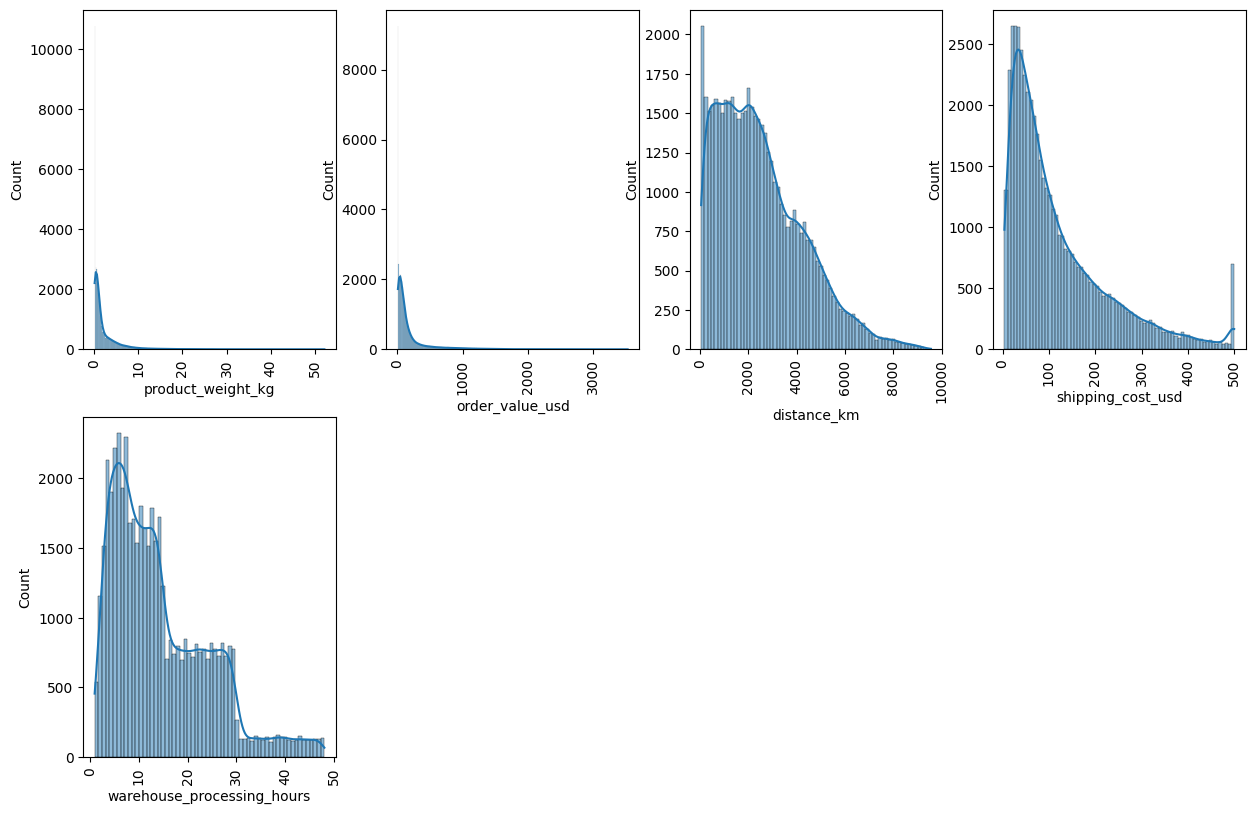

In [20]:
plt.figure(figsize=(15,15))
for i,col in enumerate(df_float.columns):
  plt.subplot(3,4,i+1)
  sns.histplot(data=df_float,x=col,kde=True)
  plt.xticks(rotation=90)
plt.show()

In [21]:
df_float.skew().sort_values(ascending=False)

,0
product_weight_kg,3.996040
order_value_usd,3.521770
shipping_cost_usd,1.490725
warehouse_processing_hours,1.043450
distance_km,0.834110


In [22]:
df_float['product_weight_kg']=np.log1p(df_float['product_weight_kg'])
df_float['order_value_usd']=np.log1p(df_float['order_value_usd'])
df_float['distance_km']=np.log1p(df_float['distance_km'])
df_float['shipping_cost_usd']=np.log1p(df_float['shipping_cost_usd'])
df_float['warehouse_processing_hours']=np.log1p(df_float['warehouse_processing_hours'])

In [23]:
df_float.skew().sort_values(ascending=False)

,0
product_weight_kg,1.067830
order_value_usd,0.272527
warehouse_processing_hours,-0.200338
shipping_cost_usd,-0.223450
distance_km,-1.280128


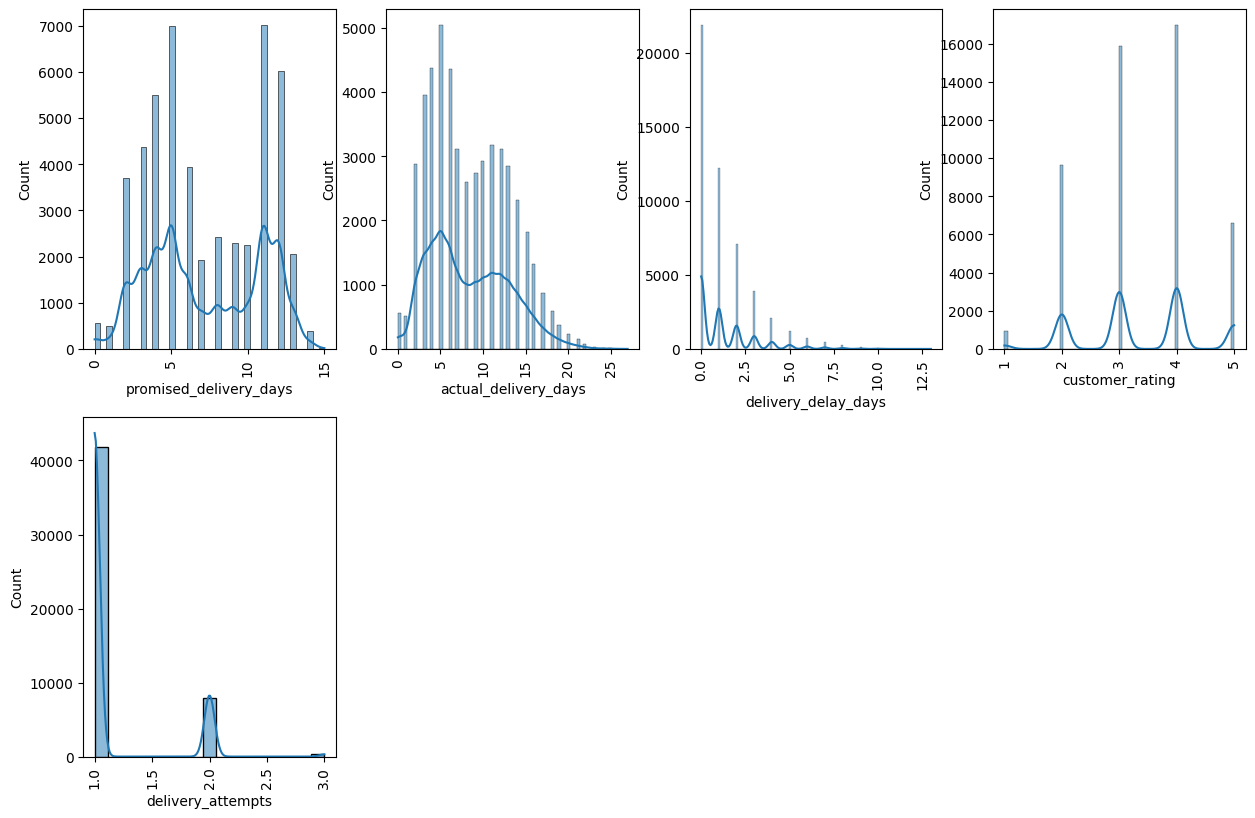

In [24]:
plt.figure(figsize=(15,15))
for i,col in enumerate(df_int.columns):
  plt.subplot(3,4,i+1)
  sns.histplot(data=df_int,x=col,kde=True)
  plt.xticks(rotation=90)
plt.show()

In [25]:
df_int.skew().sort_values(ascending=False)

,0
delivery_attempts,2.048106
delivery_delay_days,1.862027
actual_delivery_days,0.445157
promised_delivery_days,0.089675
customer_rating,-0.117179


In [26]:
df_int['delivery_attempts']=np.log1p(df_int['delivery_attempts'])
df_int['delivery_delay_days']=np.log1p(df_int['delivery_delay_days'])

In [27]:
df_int.skew().sort_values(ascending=False)

,0
delivery_attempts,1.925020
delivery_delay_days,0.567989
actual_delivery_days,0.445157
promised_delivery_days,0.089675
customer_rating,-0.117179


In [28]:
df_num=pd.concat([df_float,df_int],axis=1)

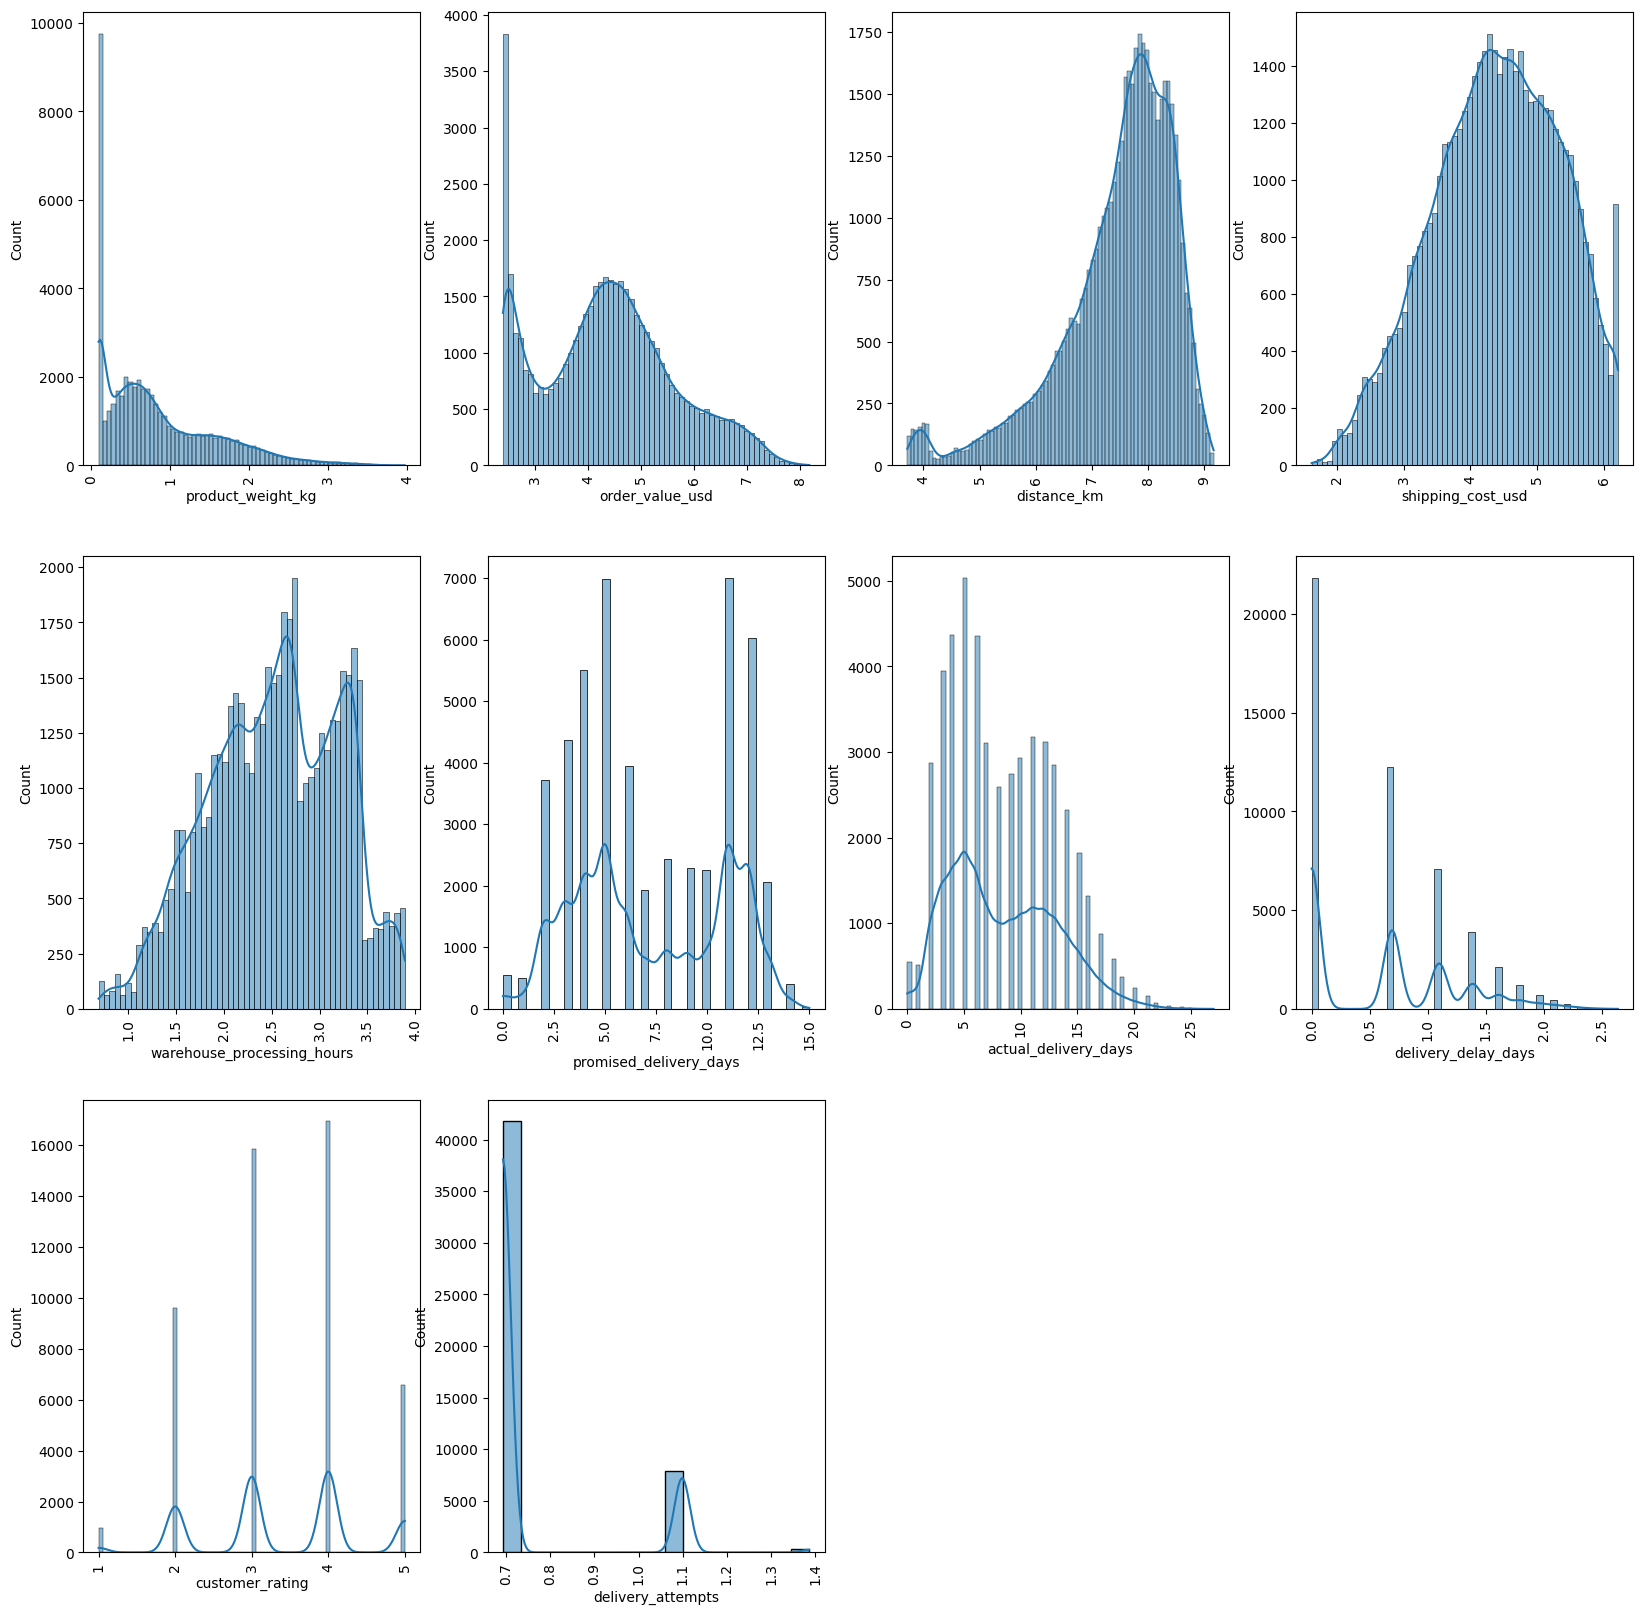

In [29]:
plt.figure(figsize=(20,20))
for i, col in enumerate(df_num.columns):

    plt.subplot(3, 4, i + 1)
    sns.histplot(data=df_num, x=col, kde=True)
    plt.xticks(rotation=90)
plt.show()


# Correlation of features

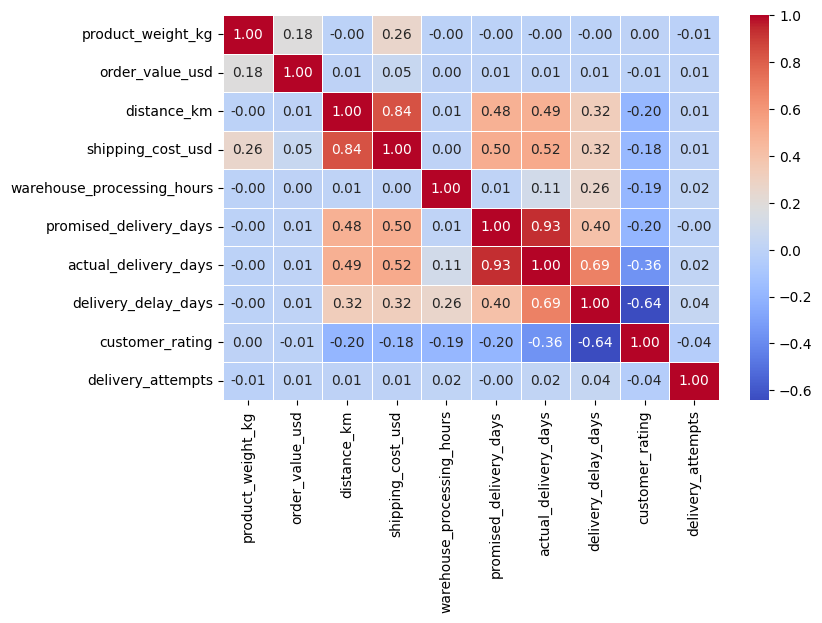

In [30]:
plt.figure(figsize=(8,5))
sns.heatmap(df_num.corr(),annot=True,cmap='coolwarm',linewidths=0.5,fmt='.2f')
plt.show()

# Outlier removal by IQR

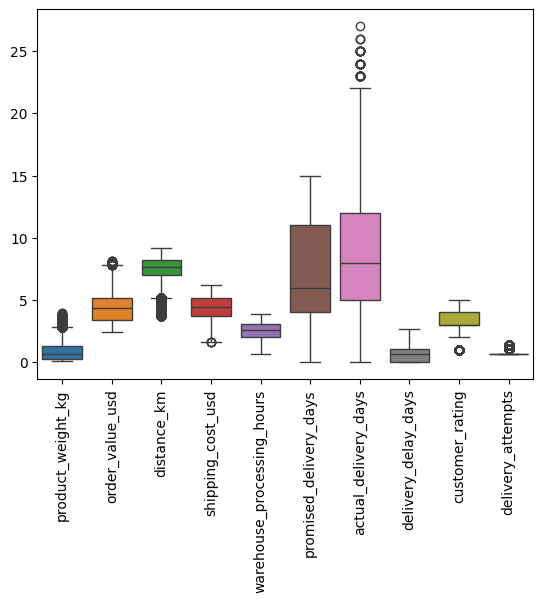

In [31]:
sns.boxplot(data=df_num)
plt.xticks(rotation=90)
plt.show()

In [32]:
Q1 = df_num.quantile(0.25)
Q3 = df_num.quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
median_value = df_num.median()

df_IQR_re = df_num.mask((df_num < lower_limit) | (df_num > upper_limit), median_value,axis=1)


In [33]:
df_IQR_re.isnull().sum()

,0
product_weight_kg,0
order_value_usd,0
distance_km,0
shipping_cost_usd,0
warehouse_processing_hours,0
promised_delivery_days,0
actual_delivery_days,0
delivery_delay_days,0
customer_rating,0
delivery_attempts,0


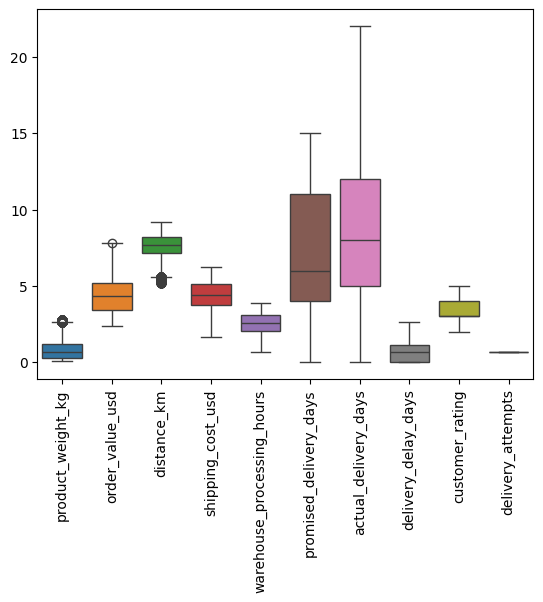

In [34]:
sns.boxplot(data=df_IQR_re)
plt.xticks(rotation=90)
plt.show()

# Train_Test_Split

In [35]:
df_final=pd.concat([df_IQR_re,df_object],axis=1)

In [36]:
df_final.shape

(50000, 25)

In [37]:
X=df_final.drop(['late_delivery','actual_delivery_days','delivery_delay_days'],axis=1)
y=pd.DataFrame(df_final['late_delivery'])

In [38]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [39]:
X_tr_int=X_train.select_dtypes(exclude='object')
X_tr_object=X_train.select_dtypes(include='object')

In [40]:
X_ts_int=X_test.select_dtypes(exclude='object')
X_ts_object=X_test.select_dtypes(include='object')

# Selecting best K features

In [41]:
selector=SelectKBest(f_classif,k=5)
X_tr_sl=selector.fit_transform(X_tr_int,y_train)
X_s=pd.DataFrame(X,columns=X_tr_int.columns[selector.get_support()])
X_ts_sl=selector.transform(X_ts_int)
X_ts_s=pd.DataFrame(X_ts_sl,columns=X_tr_int.columns[selector.get_support()])


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


# Standardizing feature

In [42]:
scale=StandardScaler()
X_tr_sc=scale.fit_transform(X_tr_sl)
X_tr_sc=pd.DataFrame(X_tr_sc,columns=X_s.columns)
X_ts_sc=scale.transform(X_ts_sl)
X_ts_sc=pd.DataFrame(X_ts_sc,columns=X_ts_s.columns)

# Encoding

In [43]:
od=OrdinalEncoder()
X_en=od.fit_transform(X_tr_object)
X_en=pd.DataFrame(X_en,columns=X_tr_object.columns)
X_ts_en=od.transform(X_ts_object)
X_ts_en=pd.DataFrame(X_ts_en,columns=X_ts_object.columns)


In [44]:
X_train_final=pd.concat([X_tr_sc,X_en],axis=1)
X_test_final=pd.concat([X_ts_sc,X_ts_en],axis=1)


In [45]:
X_test_final = X_test_final.reindex(columns=X_train_final.columns)

In [46]:
y_train_encoded=od.fit_transform(y_train)
y_test_encoded=od.transform(y_test)

# Model building,Training and evaluation

In [47]:
models={'Logistic Regression' : LogisticRegression(),
        'Decision Tree' : DecisionTreeClassifier(),
        'Random Forest' : RandomForestClassifier(),
        'KNN' : KNeighborsClassifier(),
        'Naive Bayes' : GaussianNB(),
        'SVM' : SVC(),
        'Extra Tree' : ExtraTreeClassifier(),
        'AdaBoost' : AdaBoostClassifier(),
        'Gradient Boosting' : GradientBoostingClassifier()
        }

In [48]:
result=[]
for i,model in models.items():
  model.fit(X_train_final,y_train_encoded)
  y_pred=model.predict(X_test_final)
  accuracy=accuracy_score(y_test_encoded,y_pred)
  precision=precision_score(y_test_encoded,y_pred)
  recall=recall_score(y_test_encoded,y_pred)
  f1=f1_score(y_test_encoded,y_pred)
  result.append({'Model':i,'Accuracy':accuracy,'Precision':precision,'Recall':recall,'F1 Score':f1})

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return 

In [49]:
results_df = pd.DataFrame(result)

results_df = results_df.sort_values(
    by='Accuracy',
    ascending=True
)

print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score
3                  KNN    0.7944   0.806812  0.834074  0.820217
6           Extra Tree    0.8559   0.873927  0.869109  0.871511
4          Naive Bayes    0.8756   0.895003  0.882269  0.888590
1        Decision Tree    0.8810   0.894044  0.894362  0.894203
0  Logistic Regression    0.9045   0.916637  0.913214  0.914922
5                  SVM    0.9054   0.919311  0.911791  0.915536
7             AdaBoost    0.9203   0.933214  0.924418  0.928795
2        Random Forest    0.9215   0.937274  0.922106  0.929628
8    Gradient Boosting    0.9255   0.936315  0.930820  0.933559


Cross validation and Hyperparameter tuning

In [50]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [51]:
models = {
'Logistic Regression': (LogisticRegression(max_iter=1000), { 'C': [0.01, 0.1, 1, 10],'penalty': ['l2']}),

'Decision Tree': ( DecisionTreeClassifier(random_state=42),
                 {'max_depth': [3, 5, 7, 10, None],'min_samples_split': [2, 5, 10, 20],
                   'min_samples_leaf': [1, 2, 5, 10],'criterion': ['gini']}),

'Random Forest': (RandomForestClassifier(random_state=42),
                  { 'n_estimators': [100, 200, 300],'max_depth': [5, 8, 10, 15],
                     'min_samples_split': [2, 5, 10],'min_samples_leaf': [1, 2, 5]}),
'KNN': (KNeighborsClassifier(),
            {'n_neighbors': [3, 5, 7, 9, 11],
            'weights': ['uniform', 'distance'],
            'p': [1, 2]}),
'Naive Bayes': (GaussianNB(),{'var_smoothing': [1e-11, 1e-10, 1e-9, 1e-8]}),
'SVM': (SVC(),{'C': [0.01, 0.1, 1, 10],
            'kernel': ['linear', 'rbf'],
            'gamma': ['scale', 'auto']}),
 'Extra Tree': ( ExtraTreeClassifier(random_state=42),
        {'max_depth': [3, 5, 7, 10, None],'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 5],'criterion': ['gini', 'entropy']}),
'AdaBoost': (AdaBoostClassifier(random_state=42),
        {'n_estimators': [50, 100, 150, 200],
            'learning_rate': [0.01, 0.1, 0.5, 1.0]}),
'Gradient Boosting': (GradientBoostingClassifier(random_state=42),
        {'n_estimators': [50, 100, 150],'learning_rate': [0.01, 0.05, 0.1],
          'max_depth': [2, 3, 4],'min_samples_split': [2, 5, 10],
          'min_samples_leaf': [1, 2, 5]})
}

In [52]:

best_models = {}
results = []

for name, (model, parameters) in models.items():

    print(f"Tuning {name}...")

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=parameters,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )

    grid_search.fit(X_train_final, y_train_encoded.ravel())

    best_models[name] = grid_search.best_estimator_

    results.append({
        'Model': name,
        'Best Parameters': grid_search.best_params_,
        'Best CV Accuracy': grid_search.best_score_
    })

    print("Best Parameters:", grid_search.best_params_)
    print("Best Score:", grid_search.best_score_)
    print("-" * 50)


Tuning Logistic Regression...
Best Parameters: {'C': 10, 'penalty': 'l2'}
Best Score: 0.9124000000000001
--------------------------------------------------
Tuning Decision Tree...
Best Parameters: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 20}
Best Score: 0.9187
--------------------------------------------------
Tuning Random Forest...
Best Parameters: {'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Best Score: 0.9256500000000001
--------------------------------------------------
Tuning KNN...
Best Parameters: {'n_neighbors': 11, 'p': 1, 'weights': 'distance'}
Best Score: 0.8469750000000001
--------------------------------------------------
Tuning Naive Bayes...
Best Parameters: {'var_smoothing': 1e-08}
Best Score: 0.879725
--------------------------------------------------
Tuning SVM...
Best Parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'linear'}
Best Score: 0.9112750000000001
----------------------------

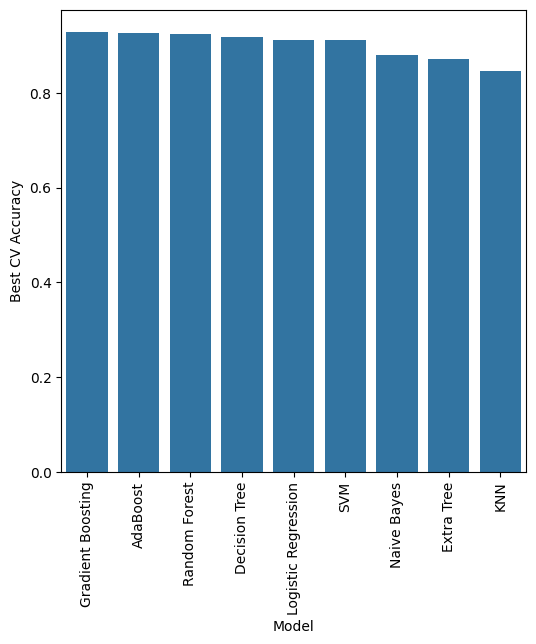

In [63]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='Best CV Accuracy',ascending=False)
plt.figure(figsize=(6, 6))
sns.barplot(data=results_df,x='Model',y='Best CV Accuracy')
plt.xticks(rotation=90)
plt.show()


Gradient boost is the best performing model


In [68]:
best_model = best_models['Gradient Boosting']

joblib.dump(best_model, 'best_model.pkl')

['best_model.pkl']